In [1]:
# --- Kütüphaneler ---
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
import time


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Kullanılan cihaz:", device)
print("PyTorch sürümü:", torch.__version__)

Kullanılan cihaz: cuda
PyTorch sürümü: 2.11.0+cu130


In [2]:
# --- Dönüşümler  ---
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# --- Veri setleri ---
train_full = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
test_set   = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# --- %80 train / %20 validation ---
val_size   = int(0.2 * len(train_full))       # 12000
train_size = len(train_full) - val_size       # 48000

generator = torch.Generator().manual_seed(42) # tekrarlanabilirlik için
train_set, val_set = random_split(train_full, [train_size, val_size], generator=generator)

print(f"Train boyutu      : {len(train_set)}")
print(f"Validation boyutu : {len(val_set)}")
print(f"Test boyutu       : {len(test_set)}")


BATCH_SIZE = 64

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False)

print("Batch sayısı (train):", len(train_loader))

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 468kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.50MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.40MB/s]

Train boyutu      : 48000
Validation boyutu : 12000
Test boyutu       : 10000
Batch sayısı (train): 750


In [3]:
# --- 3. MLP Modeli ---
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),              # [B, 1, 28, 28] -> [B, 784]
            nn.Linear(784, 512),       # Gizli katman 1
            nn.ReLU(),
            nn.Linear(512, 256),       # Gizli katman 2
            nn.ReLU(),
            nn.Linear(256, 10)         # Çıkış: 10 sınıf (softmax, loss içinde)
        )

    def forward(self, x):
        return self.net(x)

model = MLP().to(device)
print(model)

# Parametre sayısı (raporda belirtmen iyi olur)
total_params = sum(p.numel() for p in model.parameters())
print(f"\nToplam parametre sayısı: {total_params:,}")

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)

Toplam parametre sayısı: 535,818


In [4]:
# --- 4. Loss, Optimizer, Eğitim Döngüsü ---
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 15   # istersen artır/azalt

# Kayıt listeleri (grafik için)
history = {
    "train_loss": [], "val_loss": [],
    "train_acc":  [], "val_acc":  []
}

def run_epoch(loader, train=True):
    """Bir epoch boyunca ilerler; loss ve accuracy döndürür."""
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * x.size(0)
            preds = out.argmax(dim=1)
            correct += (preds == y).sum().item()
            total   += y.size(0)
    return total_loss / total, correct / total

# --- Eğitim başlıyor ---
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)

    print(f"Epoch {epoch:2d}/{EPOCHS} | "
          f"train_loss={tr_loss:.4f}  train_acc={tr_acc:.4f} | "
          f"val_loss={va_loss:.4f}  val_acc={va_acc:.4f}")

train_time = time.time() - start_time
print(f"\nToplam eğitim süresi: {train_time:.2f} saniye ({train_time/60:.2f} dakika)")

Epoch  1/15 | train_loss=0.2213  train_acc=0.9319 | val_loss=0.1508  val_acc=0.9548
Epoch  2/15 | train_loss=0.0934  train_acc=0.9709 | val_loss=0.0942  val_acc=0.9707
Epoch  3/15 | train_loss=0.0617  train_acc=0.9805 | val_loss=0.0964  val_acc=0.9717
Epoch  4/15 | train_loss=0.0498  train_acc=0.9841 | val_loss=0.0965  val_acc=0.9732
Epoch  5/15 | train_loss=0.0393  train_acc=0.9875 | val_loss=0.0958  val_acc=0.9722
Epoch  6/15 | train_loss=0.0333  train_acc=0.9889 | val_loss=0.0968  val_acc=0.9768
Epoch  7/15 | train_loss=0.0272  train_acc=0.9911 | val_loss=0.0990  val_acc=0.9782
Epoch  8/15 | train_loss=0.0253  train_acc=0.9918 | val_loss=0.1029  val_acc=0.9767
Epoch  9/15 | train_loss=0.0276  train_acc=0.9916 | val_loss=0.1119  val_acc=0.9740
Epoch 10/15 | train_loss=0.0175  train_acc=0.9939 | val_loss=0.1289  val_acc=0.9739
Epoch 11/15 | train_loss=0.0231  train_acc=0.9929 | val_loss=0.1410  val_acc=0.9718
Epoch 12/15 | train_loss=0.0162  train_acc=0.9949 | val_loss=0.1231  val_acc

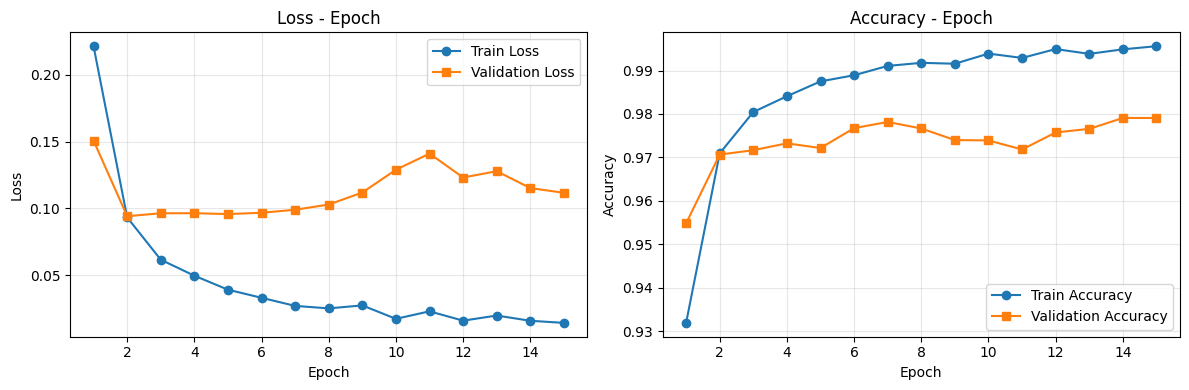

Test Loss     : 0.1047
Test Accuracy : 0.9802  (98.02%)


In [5]:

epochs = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss grafiği
axes[0].plot(epochs, history["train_loss"], marker="o", label="Train Loss")
axes[0].plot(epochs, history["val_loss"],   marker="s", label="Validation Loss")
axes[0].set_title("Loss - Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Accuracy grafiği
axes[1].plot(epochs, history["train_acc"], marker="o", label="Train Accuracy")
axes[1].plot(epochs, history["val_acc"],   marker="s", label="Validation Accuracy")
axes[1].set_title("Accuracy - Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()


test_loss, test_acc = run_epoch(test_loader, train=False)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f}  ({test_acc*100:.2f}%)")

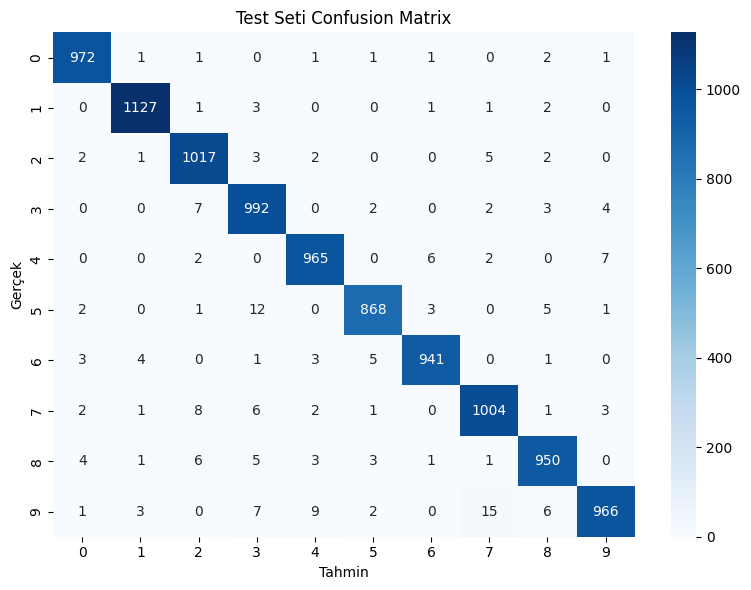

In [6]:
# --- Confusion Matrix (opsiyonel) ---
import seaborn as sns
from sklearn.metrics import confusion_matrix

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        preds = model(x).argmax(dim=1).cpu()
        all_preds.append(preds)
        all_labels.append(y)

all_preds  = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.title("Test Seti Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

Lütfen öğrenci numaranızın fotoğrafını yükleyin:


Saving Num.jpeg to Num.jpeg
Yüklenen dosya: Num.jpeg


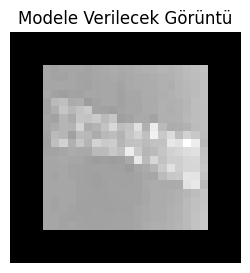

In [21]:
# --- 7. Kendi Görüntümüzü İşleme ---
from PIL import Image, ImageOps
import torchvision.transforms as T
from google.colab import files

# 1. Görüntüyü Colab'a yükle (eğer sürükle-bırak yapmadıysan bu satırı çalıştır)
print("Lütfen öğrenci numaranızın fotoğrafını yükleyin:")
uploaded = files.upload()

# 2. Yüklediğin dosyanın adını buraya yaz (örn: "numaram.jpg")
dosya_adi = list(uploaded.keys())[0]  # Otomatik alır
print(f"Yüklenen dosya: {dosya_adi}")

def preprocess_image(image_path):
    # Gri tona çevir
    img = Image.open(image_path).convert('L')

    # Renkleri ters çevir (Beyaz zemin -> Siyah zemin)
    img = ImageOps.invert(img)

    # Rakamın etrafındaki boşlukları kırp (Bounding Box)
    bbox = img.getbbox()
    if bbox:
        img = img.crop(bbox)

    # Rakamı 20x20 boyutuna getir (MNIST'te rakamlar 28x28 içinde 20x20 kaplar)
    img = img.resize((20, 20), Image.Resampling.LANCZOS)

    # 28x28'lik siyah bir tuval oluştur ve rakamı ortasına yerleştir
    yeni_img = Image.new('L', (28, 28), 0)
    yeni_img.paste(img, ((28 - 20) // 2, (28 - 20) // 2))

    return yeni_img

# Görüntüyü işle
img_28x28 = preprocess_image(dosya_adi)

# MNIST normalizasyonunu uygula
transform = T.Compose([
    T.ToTensor(),
    T.Normalize((0.1307,), (0.3081,))
])
img_tensor = transform(img_28x28).unsqueeze(0).to(device) # [1, 1, 28, 28]

# İşlenmiş görüntüyü göster
plt.figure(figsize=(3,3))
plt.imshow(img_28x28, cmap='gray')
plt.title("Modele Verilecek Görüntü")
plt.axis('off')
plt.show()

Fotoğrafta 12 adet rakam bulundu!


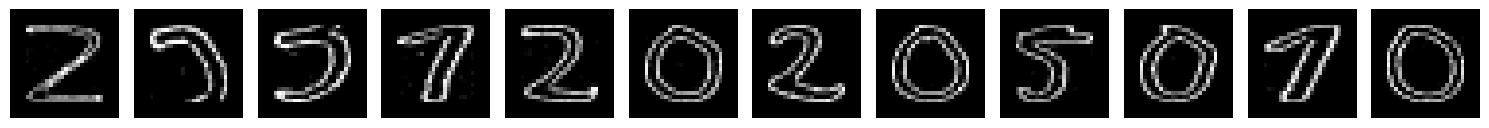

In [22]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# 1. Fotoğrafı oku
img_cv = cv2.imread(dosya_adi, cv2.IMREAD_GRAYSCALE)

# 2. Gölgeleri ve ışık dengesizliğini yok etmek için "Adaptif Thresholding" kullan
# Bu yöntem, fotoğrafın sağ tarafındaki gölgeyi görmezden gelir.
thresh = cv2.adaptiveThreshold(img_cv, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                               cv2.THRESH_BINARY_INV, 21, 10)

# 3. Morfolojik Kapatma (Closing): İnce kalem yüzünden kopan çizgileri birleştirir
kernel = np.ones((3,3), np.uint8)
thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2)

# 4. Konturları bul
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# 5. Akıllı Filtreleme: Sadece yeterince büyük alana sahip olanları (gerçek rakamları) al
bounding_boxes = []
for c in contours:
    x, y, w, h = cv2.boundingRect(c)
    alan = cv2.contourArea(c)
    # Alanı 100'den büyük, eni ve boyu 15'ten büyük olanları al (gölgeleri ve noktaları eler)
    if alan > 100 and w > 15 and h > 15:
        bounding_boxes.append((x, y, w, h))

# 6. Soldan sağa sırala
bounding_boxes = sorted(bounding_boxes, key=lambda b: b[0])

print(f"Fotoğrafta {len(bounding_boxes)} adet rakam bulundu!")

if len(bounding_boxes) == 0:
    print("HATA: Hiç rakam bulunamadı!")
else:
    islenmis_rakamlar = []

    def mnist_formatla(cropped_img):
        img_resized = cv2.resize(cropped_img, (20, 20), interpolation=cv2.INTER_AREA)
        yeni_img = np.zeros((28, 28), dtype=np.uint8)
        yeni_img[4:24, 4:24] = img_resized
        return yeni_img

    # Çizim ayarları
    fig, axes = plt.subplots(1, len(bounding_boxes), figsize=(15, 2))
    if len(bounding_boxes) == 1:
        axes = [axes]

    for i, (x, y, w, h) in enumerate(bounding_boxes):
        cropped = thresh[y:y+h, x:x+w]
        islenmis = mnist_formatla(cropped)
        islenmis_rakamlar.append(islenmis)

        axes[i].imshow(islenmis, cmap='gray')
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

In [23]:
# --- 10. Tüm Rakamları Tahmin Et ---
model.eval()

# Normalizasyon ayarı (Hücre 7'de kullandığımız)
normalize = T.Normalize((0.1307,), (0.3081,))

tahminler = []

with torch.no_grad():
    for i, img in enumerate(islenmis_rakamlar):
        # Numpy array'i PyTorch tensorüne çevir, normalize et ve boyut ekle [1, 1, 28, 28]
        tensor_img = T.ToTensor()(img)
        tensor_img = normalize(tensor_img).unsqueeze(0).to(device)

        # Modelden tahmin al
        output = model(tensor_img)
        pred = output.argmax(dim=1).item()
        tahminler.append(str(pred))

# Sonuçları yazdır
gercek_numara = "".join(tahminler)
print(f"✍️ Modelin Okuduğu Numara: {gercek_numara}")
print(f"👤 Senin Yazdığın Numara : 23120205010")

✍️ Modelin Okuduğu Numara: 232220205080
👤 Senin Yazdığın Numara : 23120205010
